# Week 3 - Statistical Analysis and Hypothesis Testing

**Dataset:** cleaned IBM Telco Customer Churn data from Week 1 (7,043 customers).

This notebook runs `src/05_statistical_analysis.py`. It tests the three questions
raised by the Week 2 visual story: contract type and churn (primary hypothesis,
including a tenure-stratified check), monthly charges of churned vs retained
customers, and the security / tech-support add-on gaps. The code cells are taken
directly from `src/`.


In [1]:
import sys
sys.path.insert(0, "../src")  # make the project modules in src/ importable
%config InlineBackend.figure_format = 'retina'

## Week 3 - Statistical analysis and hypothesis testing

The Week 2 visual story ended with three questions. Each is tested here with a
method chosen for the type of variables involved:

| | Question | Variables | Main test |
|---|---|---|---|
| A (primary) | Is churn associated with contract type? | categorical x categorical | Chi-square test of independence (+ Cochran-Mantel-Haenszel check controlling for tenure) |
| B | Do churned and retained customers differ in monthly charges? | numeric by two groups | Welch's t-test (+ Mann-Whitney U as a robustness check) |
| C | Is churn lower for internet customers with online security / tech support? | two proportions | Two-proportion z-test with Newcombe CI |

Significance level: alpha = 0.05 (two-sided) for every test. Where several
related comparisons are made, p-values are adjusted with the Holm method.

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter, StrMethodFormatter
from scipy import stats
from statsmodels.stats.contingency_tables import StratifiedTable, Table, Table2x2
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import confint_proportions_2indep, proportion_confint, proportions_ztest

from config import RANDOM_SEED, RESULTS_DIR, TABLE_DIR
from data_utils import CONTRACT_ORDER, load_clean_data
from plot_style import (CHURN_COLOR, INK, MUTED_INK, ORDINAL_BLUES, RETAINED_COLOR,
                        SEQUENTIAL_CMAP, apply_style, save_figure)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)
apply_style()
ALPHA = 0.05
df = load_clean_data()
results = {"alpha": ALPHA, "n_customers": len(df)}
print(f"{len(df):,} customers; churned = {df['churn_flag'].sum():,}")


def p_text(p):
    """Readable p-value: 3 significant figures, or '<1e-300' when it underflows to 0."""
    return "<1e-300" if p == 0 else f"{p:.3g}"


def records(frame, p_columns=("p_value", "p_holm")):
    """Rows as dicts for the JSON file; p-values are kept at full precision (never rounded)."""
    rounded = frame.copy()
    for column in rounded.columns:
        if column not in p_columns and pd.api.types.is_float_dtype(rounded[column]):
            rounded[column] = rounded[column].round(6)
    return rounded.to_dict("records")


def show(frame, p_columns=("p_value", "p_holm")):
    """Display a results table with p-values in scientific notation (not rounded to 0.0)."""
    shown = frame.copy()
    for column in p_columns:
        if column in shown:
            shown[column] = shown[column].map(p_text)
    display(shown.round(3))

7,043 customers; churned = 1,869


### Hypothesis A - Contract type and churn (primary)

**Research question:** Is a customer's churn status associated with their contract type?

* **H0:** Churn is independent of contract type - the churn rate is the same for
  month-to-month, one-year and two-year customers.
* **H1:** Churn is not independent of contract type - at least one contract type
  has a different churn rate.
* alpha = 0.05

**Test:** Pearson chi-square test of independence (both variables categorical).
**Assumptions:** (1) each customer appears once (independent observations -
customerID is unique, checked in Week 1); (2) categories are mutually
exclusive; (3) every expected cell count is at least 5.

In [3]:
observed = pd.crosstab(df["Contract"], df["Churn"])[["No", "Yes"]]
chi2, p_value, dof, expected = stats.chi2_contingency(observed, correction=False)
expected = pd.DataFrame(expected, index=observed.index, columns=observed.columns)
n_total = observed.to_numpy().sum()
cramers_v = np.sqrt(chi2 / (n_total * (min(observed.shape) - 1)))

print("Observed counts:")
display(observed)
print("Expected counts if H0 were true:")
display(expected.round(1))
print(f"Smallest expected count: {expected.to_numpy().min():.1f} (assumption: >= 5)")
print(f"Chi-square = {chi2:.2f}, df = {dof}, p-value: {p_text(p_value)}")
print(f"Cramer's V = {cramers_v:.3f}")
print("Decision:", "reject H0" if p_value < ALPHA else "fail to reject H0")

Observed counts:


Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


Expected counts if H0 were true:


Churn,No,Yes
Contract,,
Month-to-month,2846.7,1028.3
One year,1082.1,390.9
Two year,1245.2,449.8


Smallest expected count: 390.9 (assumption: >= 5)
Chi-square = 1184.60, df = 2, p-value: 5.86e-258
Cramer's V = 0.410
Decision: reject H0


In [4]:
# Where does the association come from? Adjusted (standardised) residuals:
# values beyond +/-1.96 mark cells that differ from H0 at the 5% level.
adjusted_residuals = pd.DataFrame(Table(observed.to_numpy()).standardized_resids,
                                  index=observed.index, columns=observed.columns)
display(adjusted_residuals.round(2))

results["A"] = {
    "observed": observed.to_dict("index"), "expected": expected.round(2).to_dict("index"),
    "min_expected": round(float(expected.to_numpy().min()), 2),
    "chi2": round(float(chi2), 3), "dof": int(dof), "p_value": float(p_value),
    "cramers_v": round(float(cramers_v), 4), "reject_h0": bool(p_value < ALPHA),
    "adjusted_residuals": adjusted_residuals.round(3).to_dict("index"),
}

Churn,No,Yes
Contract,,
Month-to-month,-34.00,34.00
One year,14.92,-14.92
Two year,25.37,-25.37


In [5]:
# Churn rate and 95% Wilson confidence interval for each contract type
group = df.groupby("Contract", observed=True)["churn_flag"].agg(churned="sum", customers="size")
group["rate"] = group["churned"] / group["customers"]
low, high = proportion_confint(group["churned"], group["customers"], alpha=ALPHA, method="wilson")
group["ci_low"], group["ci_high"] = np.asarray(low), np.asarray(high)
display((group[["rate", "ci_low", "ci_high"]] * 100).round(2).join(group[["churned", "customers"]]))

# Pairwise differences: two-proportion z-tests, Newcombe CIs, Holm-adjusted p-values
pairs = [("Month-to-month", "One year"), ("Month-to-month", "Two year"), ("One year", "Two year")]
pair_rows = []
for first, second in pairs:
    c1, n1 = group.loc[first, "churned"], group.loc[first, "customers"]
    c2, n2 = group.loc[second, "churned"], group.loc[second, "customers"]
    z, p = proportions_ztest([c1, c2], [n1, n2])
    ci_low, ci_high = confint_proportions_2indep(c1, n1, c2, n2, method="newcomb", compare="diff")
    pair_rows.append({"comparison": f"{first} vs {second}", "difference_pp": (c1 / n1 - c2 / n2) * 100,
                      "ci_low_pp": ci_low * 100, "ci_high_pp": ci_high * 100, "z": z, "p_value": p})
pairwise = pd.DataFrame(pair_rows)
pairwise["p_holm"] = multipletests(pairwise["p_value"], method="holm")[1]
show(pairwise)

group.round(5).to_csv(TABLE_DIR / "contract_churn_rates_ci.csv")
pairwise.to_csv(TABLE_DIR / "contract_pairwise_differences.csv", index=False)
results["A"]["group_rates"] = {k: {"churned": int(v.churned), "customers": int(v.customers),
                                   "rate_pct": round(v.rate * 100, 2), "ci_low_pct": round(v.ci_low * 100, 2),
                                   "ci_high_pct": round(v.ci_high * 100, 2)} for k, v in group.iterrows()}
results["A"]["pairwise"] = records(pairwise)

,rate,ci_low,ci_high,churned,customers
Contract,,,,,
Month-to-month,42.71,41.16,44.27,1655,3875
One year,11.27,9.75,12.99,166,1473
Two year,2.83,2.14,3.73,48,1695


,comparison,difference_pp,ci_low_pp,ci_high_pp,z,p_value,p_holm
0,Month-to-month vs One year,31.440,29.128,33.618,21.675,3.53e-104,7.06e-104
1,Month-to-month vs Two year,39.878,38.085,41.587,29.722,3.93e-194,1.18e-193
2,One year vs Two year,8.438,6.674,10.288,9.438,3.79e-21,3.79e-21


Saved figure: outputs/figures/fig3_1_contract_rates_and_residuals.png


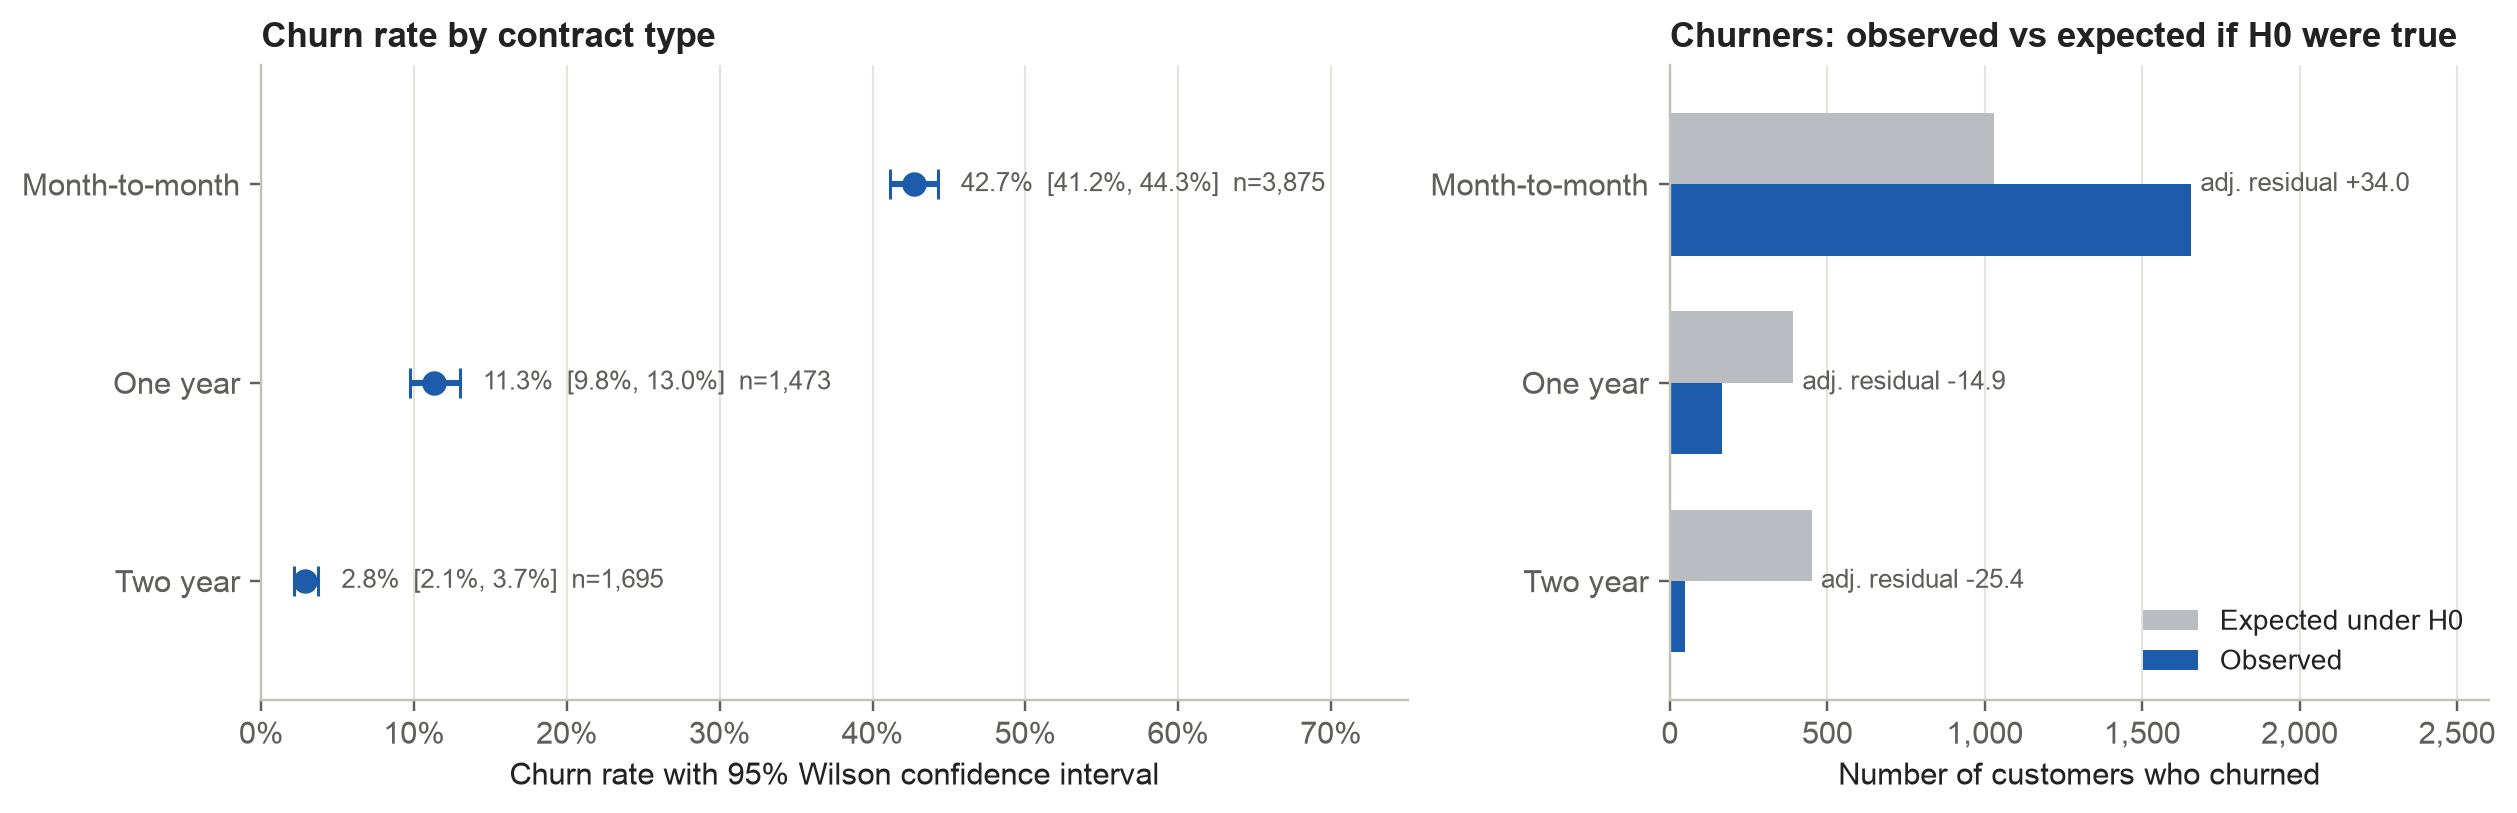

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
y = np.arange(len(group))[::-1]
ax.errorbar(group["rate"] * 100, y, xerr=[(group["rate"] - group["ci_low"]) * 100,
                                         (group["ci_high"] - group["rate"]) * 100],
            fmt="o", color=CHURN_COLOR, ecolor=CHURN_COLOR, elinewidth=2, capsize=5, markersize=7)
for yy, (_, row) in zip(y, group.iterrows()):
    ax.text(row["ci_high"] * 100 + 1.5, yy, f"{row['rate']:.1%}  [{row['ci_low']:.1%}, {row['ci_high']:.1%}]"
            f"  n={int(row['customers']):,}", va="center", fontsize=8.5, color=MUTED_INK)
ax.set_yticks(y)
ax.set_yticklabels(group.index)
ax.set_ylim(-0.6, 2.6)
ax.set_xlim(0, 75)
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set_xlabel("Churn rate with 95% Wilson confidence interval")
ax.set_title("Churn rate by contract type")
ax.grid(axis="y", visible=False)

# Observed churners vs the number expected if churn were independent of contract
ax = axes[1]
height = 0.36
ax.barh(y + height / 2, expected["Yes"], height=height, color=RETAINED_COLOR, label="Expected under H0")
ax.barh(y - height / 2, observed["Yes"], height=height, color=CHURN_COLOR, label="Observed")
for yy, contract in zip(y, observed.index):
    ax.text(max(observed.loc[contract, "Yes"], expected.loc[contract, "Yes"]) + 30, yy,
            f"adj. residual {adjusted_residuals.loc[contract, 'Yes']:+.1f}", va="center", fontsize=8.5,
            color=MUTED_INK)
ax.set_yticks(y)
ax.set_yticklabels(observed.index)
ax.set_ylim(-0.6, 2.6)
ax.set_xlim(0, 2600)
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.set_xlabel("Number of customers who churned")
ax.set_title("Churners: observed vs expected if H0 were true")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
fig.tight_layout()
save_figure(fig, "fig3_1_contract_rates_and_residuals.png")

#### Does the contract association hold when tenure is taken into account?

Month-to-month customers tend to be newer (Week 2), and newer customers churn
more. The Cochran-Mantel-Haenszel (CMH) test compares month-to-month customers
with customers on one- or two-year contracts *within* each 12-month tenure band,
then combines the bands.

* **H0:** Within tenure bands, the odds of churn do not differ between
  month-to-month and longer contracts (common odds ratio = 1).
* **H1:** The common odds ratio differs from 1.

In [7]:
df["tenure_band"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 36, 48, 60, 72],
                           labels=["0-12", "13-24", "25-36", "37-48", "49-60", "61-72"])
df["month_to_month"] = np.where(df["Contract"] == "Month-to-month", "Month-to-month", "One/two year")

strata, stratum_rows = [], []
for band, subset in df.groupby("tenure_band", observed=True):
    # rows: month-to-month, longer contract; columns: churned, stayed
    table = pd.crosstab(subset["month_to_month"], subset["Churn"]).loc[
        ["Month-to-month", "One/two year"], ["Yes", "No"]].to_numpy()
    strata.append(table)
    t2 = Table2x2(table)
    lo, hi = t2.oddsratio_confint()
    stratum_rows.append({"tenure_band": band, "odds_ratio": t2.oddsratio, "ci_low": lo, "ci_high": hi,
                         "m2m_rate_pct": table[0, 0] / table[0].sum() * 100,
                         "longer_rate_pct": table[1, 0] / table[1].sum() * 100,
                         "n": int(table.sum())})
by_stratum = pd.DataFrame(stratum_rows)
display(by_stratum.round(2))

cmh = StratifiedTable(strata)
cmh_test = cmh.test_null_odds(correction=False)
# statsmodels computes this p-value as 1 - cdf, which underflows to 0 for large statistics;
# the chi-square survival function gives the same quantity without losing precision.
cmh_p = stats.chi2.sf(cmh_test.statistic, df=1)
pooled_or = cmh.oddsratio_pooled
pooled_low, pooled_high = cmh.oddsratio_pooled_confint()
homogeneity = cmh.test_equal_odds()
print(f"CMH chi-square = {cmh_test.statistic:.2f}, df = 1, p-value: {p_text(cmh_p)}")
print(f"Mantel-Haenszel pooled odds ratio = {pooled_or:.2f} (95% CI {pooled_low:.2f}-{pooled_high:.2f})")
print(f"Breslow-Day test of equal odds ratios across bands: chi-square = {homogeneity.statistic:.2f}, "
      f"p-value: {p_text(homogeneity.pvalue)}")

by_stratum.round(4).to_csv(TABLE_DIR / "cmh_odds_ratios_by_tenure_band.csv", index=False)
results["A_cmh"] = {"statistic": round(float(cmh_test.statistic), 3), "p_value": float(cmh_p),
                    "pooled_or": round(float(pooled_or), 3), "pooled_or_ci": [round(float(pooled_low), 3),
                                                                              round(float(pooled_high), 3)],
                    "breslow_day_statistic": round(float(homogeneity.statistic), 3),
                    "breslow_day_p": float(homogeneity.pvalue),
                    "strata": by_stratum.round(4).to_dict("records")}

,tenure_band,odds_ratio,ci_low,ci_high,m2m_rate_pct,longer_rate_pct,n
0,0-12,14.54,8.22,25.70,51.35,6.77,2186
1,13-24,10.26,6.06,17.36,37.72,5.57,1024
2,25-36,7.09,4.43,11.37,32.51,6.36,832
3,37-48,5.27,3.52,7.88,33.54,8.74,762
4,49-60,3.80,2.55,5.66,27.78,9.20,832
5,61-72,5.09,3.05,8.52,22.22,5.31,1407


CMH chi-square = 482.76, df = 1, p-value: 5.37e-107
Mantel-Haenszel pooled odds ratio = 7.11 (95% CI 5.87-8.61)
Breslow-Day test of equal odds ratios across bands: chi-square = 21.66, p-value: 0.000608


Saved figure: outputs/figures/fig3_2_cmh_odds_ratios_by_tenure.png


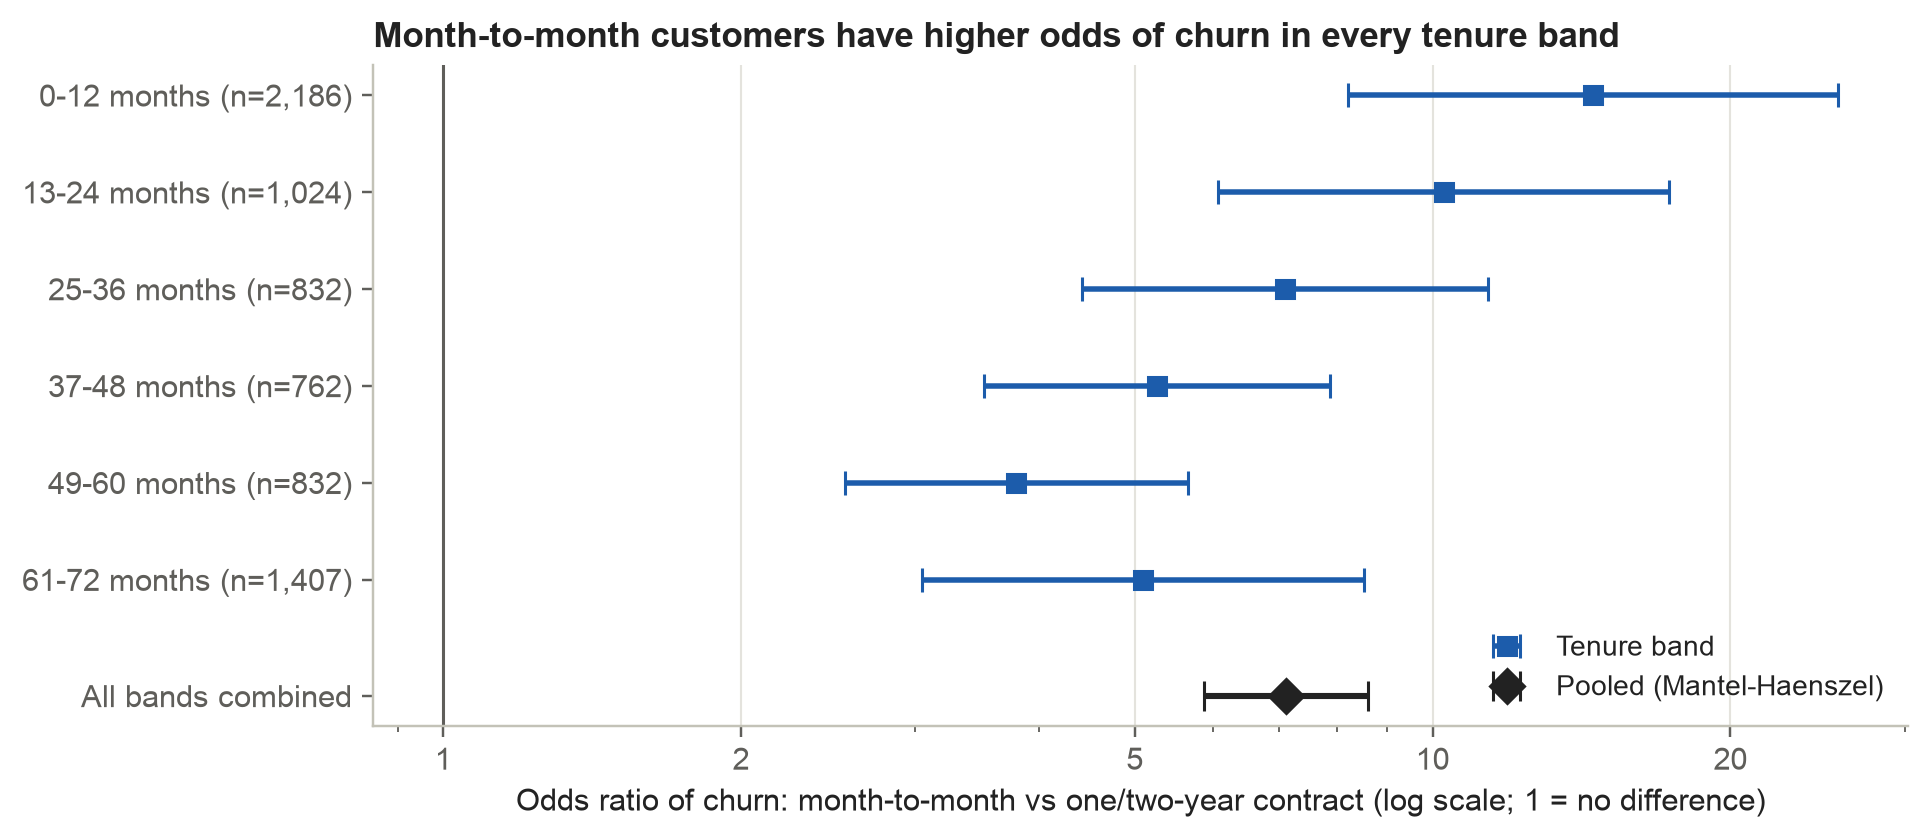

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.9))
y = np.arange(len(by_stratum))[::-1]
ax.errorbar(by_stratum["odds_ratio"], y, xerr=[by_stratum["odds_ratio"] - by_stratum["ci_low"],
                                              by_stratum["ci_high"] - by_stratum["odds_ratio"]],
            fmt="s", color=CHURN_COLOR, elinewidth=1.8, capsize=4, markersize=6, label="Tenure band")
ax.errorbar([pooled_or], [-1.2], xerr=[[pooled_or - pooled_low], [pooled_high - pooled_or]],
            fmt="D", color=INK, elinewidth=2, capsize=5, markersize=8, label="Pooled (Mantel-Haenszel)")
ax.axvline(1, color=MUTED_INK, linewidth=1)
ax.set_xscale("log")
ax.set_xticks([1, 2, 5, 10, 20])
ax.get_xaxis().set_major_formatter(StrMethodFormatter("{x:g}"))
ax.set_yticks(list(y) + [-1.2])
ax.set_yticklabels([f"{b} months (n={n:,})" for b, n in zip(by_stratum["tenure_band"], by_stratum["n"])]
                   + ["All bands combined"])
ax.set_xlabel("Odds ratio of churn: month-to-month vs one/two-year contract (log scale; 1 = no difference)")
ax.set_title("Month-to-month customers have higher odds of churn in every tenure band")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
save_figure(fig, "fig3_2_cmh_odds_ratios_by_tenure.png")

### Hypothesis B - Monthly charges of churned vs retained customers

**Research question:** Do customers who churned pay a different amount per month
from customers who stayed?

* **H0:** The mean monthly charge is the same for churned and retained customers.
* **H1:** The mean monthly charges differ (two-sided).
* alpha = 0.05

First the assumptions of a two-sample t-test are checked: independence (one row
per customer), approximate normality of the sampling distribution, equal
variances, and outliers.

In [9]:
churned_charges = df.loc[df["Churn"] == "Yes", "MonthlyCharges"].to_numpy()
retained_charges = df.loc[df["Churn"] == "No", "MonthlyCharges"].to_numpy()

descriptives = pd.DataFrame({
    name: {"n": len(x), "mean": x.mean(), "median": np.median(x), "std": x.std(ddof=1),
           "skewness": stats.skew(x), "excess_kurtosis": stats.kurtosis(x)}
    for name, x in (("Churned", churned_charges), ("Retained", retained_charges))}).T
display(descriptives.round(3))

# Normality: D'Agostino-Pearson test (Shapiro-Wilk is not reliable for n > 5,000).
# With samples this large even trivial departures are "significant", so the
# histograms and Q-Q plots below carry more weight than these p-values.
normality = {name: stats.normaltest(x) for name, x in (("Churned", churned_charges),
                                                       ("Retained", retained_charges))}
for name, res in normality.items():
    print(f"Normality test ({name}): statistic = {res.statistic:.1f}, p-value: {p_text(res.pvalue)}")

# Equal variances: Levene's test (median-centred, i.e. Brown-Forsythe - robust to non-normality)
levene = stats.levene(churned_charges, retained_charges, center="median")
print(f"Levene (Brown-Forsythe) test: W = {levene.statistic:.2f}, p-value: {p_text(levene.pvalue)}")
print(f"Variance ratio (retained / churned) = {retained_charges.var(ddof=1) / churned_charges.var(ddof=1):.2f}")


# Outliers by the 1.5 x IQR rule within each group
def iqr_outliers(x):
    q1, q3 = np.percentile(x, [25, 75])
    return int(((x < q1 - 1.5 * (q3 - q1)) | (x > q3 + 1.5 * (q3 - q1))).sum())


print("IQR outliers - churned:", iqr_outliers(churned_charges), "| retained:", iqr_outliers(retained_charges))

,n,mean,median,std,skewness,excess_kurtosis
Churned,1869.0,74.441,79.650,24.666,-0.729,-0.364
Retained,5174.0,61.265,64.425,31.093,-0.025,-1.355


Normality test (Churned): statistic = 150.4, p-value: 2.18e-33
Normality test (Retained): statistic = 103168.9, p-value: <1e-300
Levene (Brown-Forsythe) test: W = 361.84, p-value: 1.03e-78
Variance ratio (retained / churned) = 1.59
IQR outliers - churned: 0 | retained: 0


Saved figure: outputs/figures/fig3_3_monthly_charges_assumption_checks.png


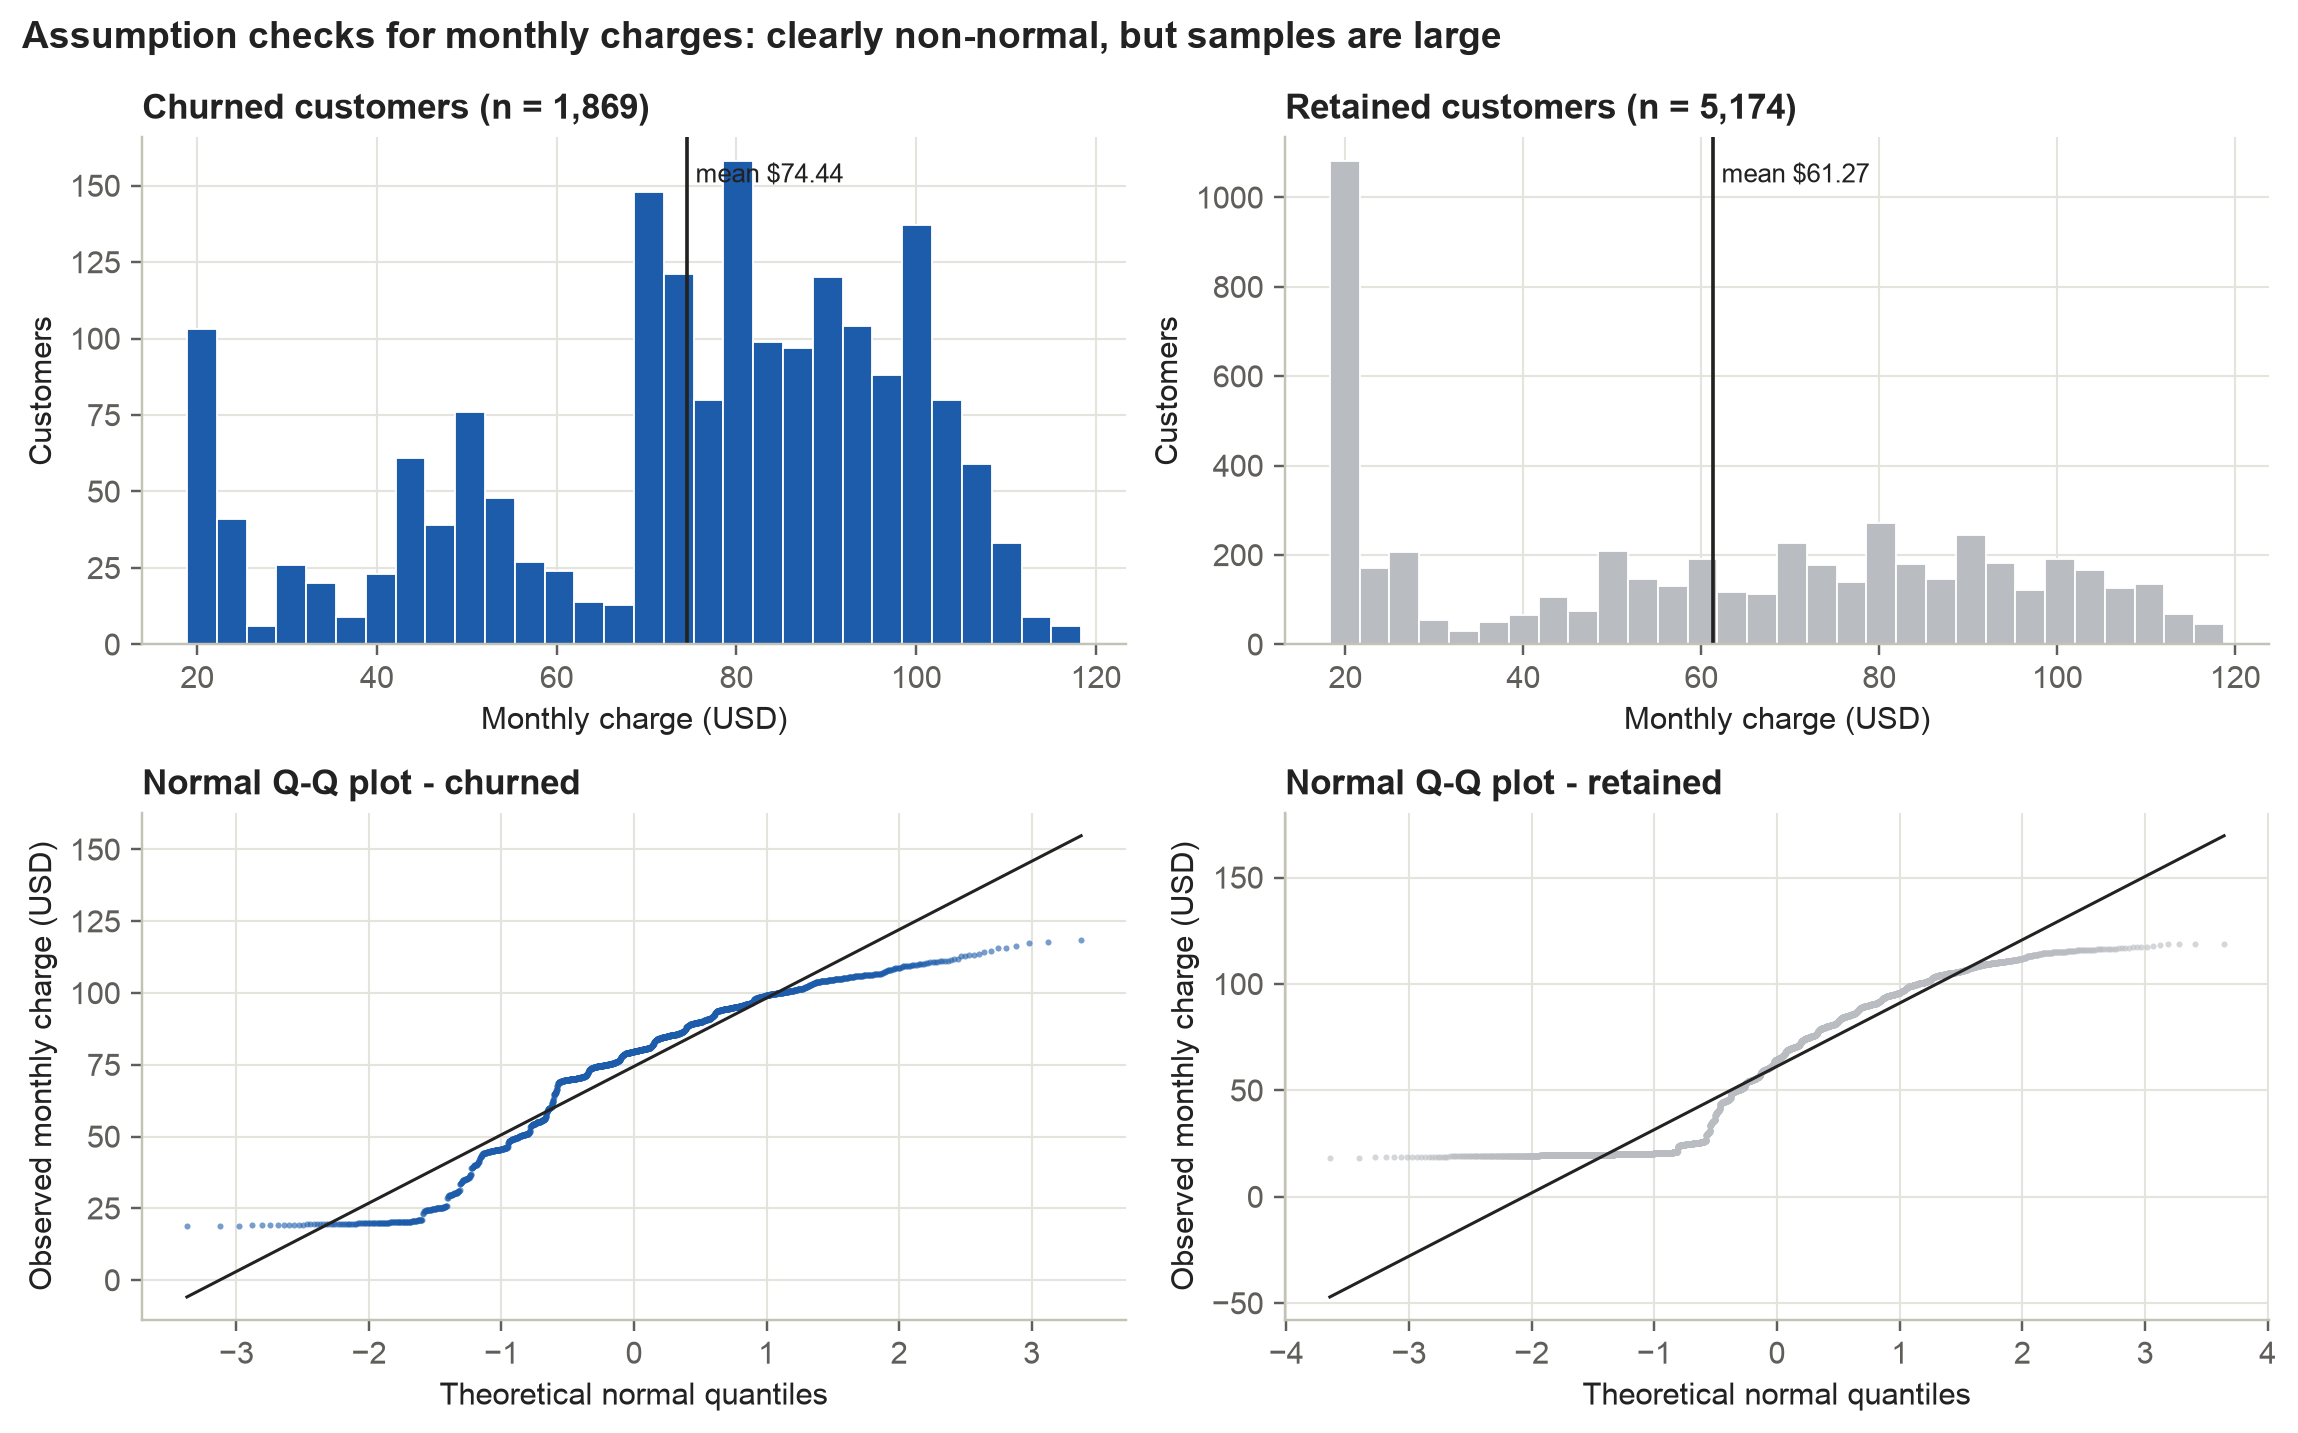

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 6.6))
for column, (name, x, colour) in enumerate((("Churned", churned_charges, CHURN_COLOR),
                                            ("Retained", retained_charges, RETAINED_COLOR))):
    ax = axes[0, column]
    ax.hist(x, bins=30, color=colour, edgecolor="white", linewidth=0.6)
    ax.axvline(x.mean(), color=INK, linewidth=1.2)
    ax.text(x.mean() + 1, ax.get_ylim()[1] * 0.95, f"mean ${x.mean():.2f}", fontsize=8.5, va="top")
    ax.set_title(f"{name} customers (n = {len(x):,})")
    ax.set_xlabel("Monthly charge (USD)")
    ax.set_ylabel("Customers")
    ax = axes[1, column]
    (theoretical, ordered), (slope, intercept, _) = stats.probplot(x, dist="norm")
    ax.scatter(theoretical, ordered, s=4, color=colour, alpha=0.6, linewidths=0)
    ax.plot(theoretical, slope * np.asarray(theoretical) + intercept, color=INK, linewidth=1)
    ax.set_title(f"Normal Q-Q plot - {name.lower()}")
    ax.set_xlabel("Theoretical normal quantiles")
    ax.set_ylabel("Observed monthly charge (USD)")
fig.suptitle("Assumption checks for monthly charges: clearly non-normal, but samples are large",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
save_figure(fig, "fig3_3_monthly_charges_assumption_checks.png")

**Test choice.** Monthly charges are not normally distributed (both groups are
skewed with several peaks) and the variances differ. With 1,869 and 5,174
customers, however, the sampling distribution of each *mean* is close to
normal (central limit theorem), so a t-test on the means remains valid.
Welch's version is used because it does not assume equal variances. A
Mann-Whitney U test, which uses ranks instead of values, is run as a
robustness check, and a bootstrap confidence interval (seed 42) checks the
t-based interval without relying on normality.

In [11]:
welch = stats.ttest_ind(churned_charges, retained_charges, equal_var=False)
welch_ci = welch.confidence_interval(confidence_level=1 - ALPHA)
mean_difference = churned_charges.mean() - retained_charges.mean()

# Effect size: Hedges' g (standardised mean difference, small-sample corrected)
n1, n2 = len(churned_charges), len(retained_charges)
pooled_sd = np.sqrt(((n1 - 1) * churned_charges.var(ddof=1) + (n2 - 1) * retained_charges.var(ddof=1))
                    / (n1 + n2 - 2))
hedges_g = mean_difference / pooled_sd * (1 - 3 / (4 * (n1 + n2) - 9))
g_se = np.sqrt((n1 + n2) / (n1 * n2) + hedges_g ** 2 / (2 * (n1 + n2)))
g_ci = (hedges_g - 1.96 * g_se, hedges_g + 1.96 * g_se)

print(f"Mean difference (churned - retained) = ${mean_difference:.2f}")
print(f"Welch t = {welch.statistic:.2f}, df = {welch.df:.1f}, p-value: {p_text(welch.pvalue)}")
print(f"95% CI for the difference: ${welch_ci.low:.2f} to ${welch_ci.high:.2f}")
print(f"Hedges' g = {hedges_g:.3f} (95% CI {g_ci[0]:.3f} to {g_ci[1]:.3f})")
print("Decision:", "reject H0" if welch.pvalue < ALPHA else "fail to reject H0")

Mean difference (churned - retained) = $13.18
Welch t = 18.41, df = 4135.8, p-value: 8.59e-73
95% CI for the difference: $11.77 to $14.58
Hedges' g = 0.446 (95% CI 0.393 to 0.500)
Decision: reject H0


In [12]:
# Robustness 1: Mann-Whitney U (rank-based, no normality assumption)
mwu = stats.mannwhitneyu(churned_charges, retained_charges, alternative="two-sided")
prob_superiority = mwu.statistic / (n1 * n2)          # P(random churned charge > random retained charge)
rank_biserial = 2 * prob_superiority - 1
print(f"Mann-Whitney U = {mwu.statistic:,.0f}, p-value: {p_text(mwu.pvalue)}")
print(f"Probability of superiority = {prob_superiority:.3f}; rank-biserial r = {rank_biserial:.3f}")

# Robustness 2: bootstrap CI for the difference in means (percentile method, fixed seed)
rng = np.random.default_rng(RANDOM_SEED)
bootstrap = stats.bootstrap((churned_charges, retained_charges),
                            statistic=lambda a, b, axis: np.mean(a, axis=axis) - np.mean(b, axis=axis),
                            n_resamples=10_000, method="percentile", vectorized=True, rng=rng)
boot_ci = bootstrap.confidence_interval
print(f"Bootstrap 95% CI for the difference: ${boot_ci.low:.2f} to ${boot_ci.high:.2f}")

results["B"] = {
    "descriptives": descriptives.round(4).to_dict("index"),
    "normality": {k: {"statistic": round(float(v.statistic), 2), "p_value": float(v.pvalue)}
                  for k, v in normality.items()},
    "levene_W": round(float(levene.statistic), 3), "levene_p": float(levene.pvalue),
    "variance_ratio": round(float(retained_charges.var(ddof=1) / churned_charges.var(ddof=1)), 3),
    "iqr_outliers": {"churned": iqr_outliers(churned_charges), "retained": iqr_outliers(retained_charges)},
    "mean_difference": round(float(mean_difference), 3),
    "welch_t": round(float(welch.statistic), 3), "welch_df": round(float(welch.df), 1),
    "welch_p": float(welch.pvalue), "welch_ci": [round(float(welch_ci.low), 3), round(float(welch_ci.high), 3)],
    "hedges_g": round(float(hedges_g), 4), "hedges_g_ci": [round(float(g_ci[0]), 4), round(float(g_ci[1]), 4)],
    "mwu_U": float(mwu.statistic), "mwu_p": float(mwu.pvalue),
    "prob_superiority": round(float(prob_superiority), 4), "rank_biserial": round(float(rank_biserial), 4),
    "bootstrap_ci": [round(float(boot_ci.low), 3), round(float(boot_ci.high), 3)],
    "bootstrap_resamples": 10_000, "reject_h0": bool(welch.pvalue < ALPHA),
}

Mann-Whitney U = 6,003,126, p-value: 3.31e-54
Probability of superiority = 0.621; rank-biserial r = 0.242


Bootstrap 95% CI for the difference: $11.80 to $14.56


Saved figure: outputs/figures/fig3_4_mean_difference_ci.png


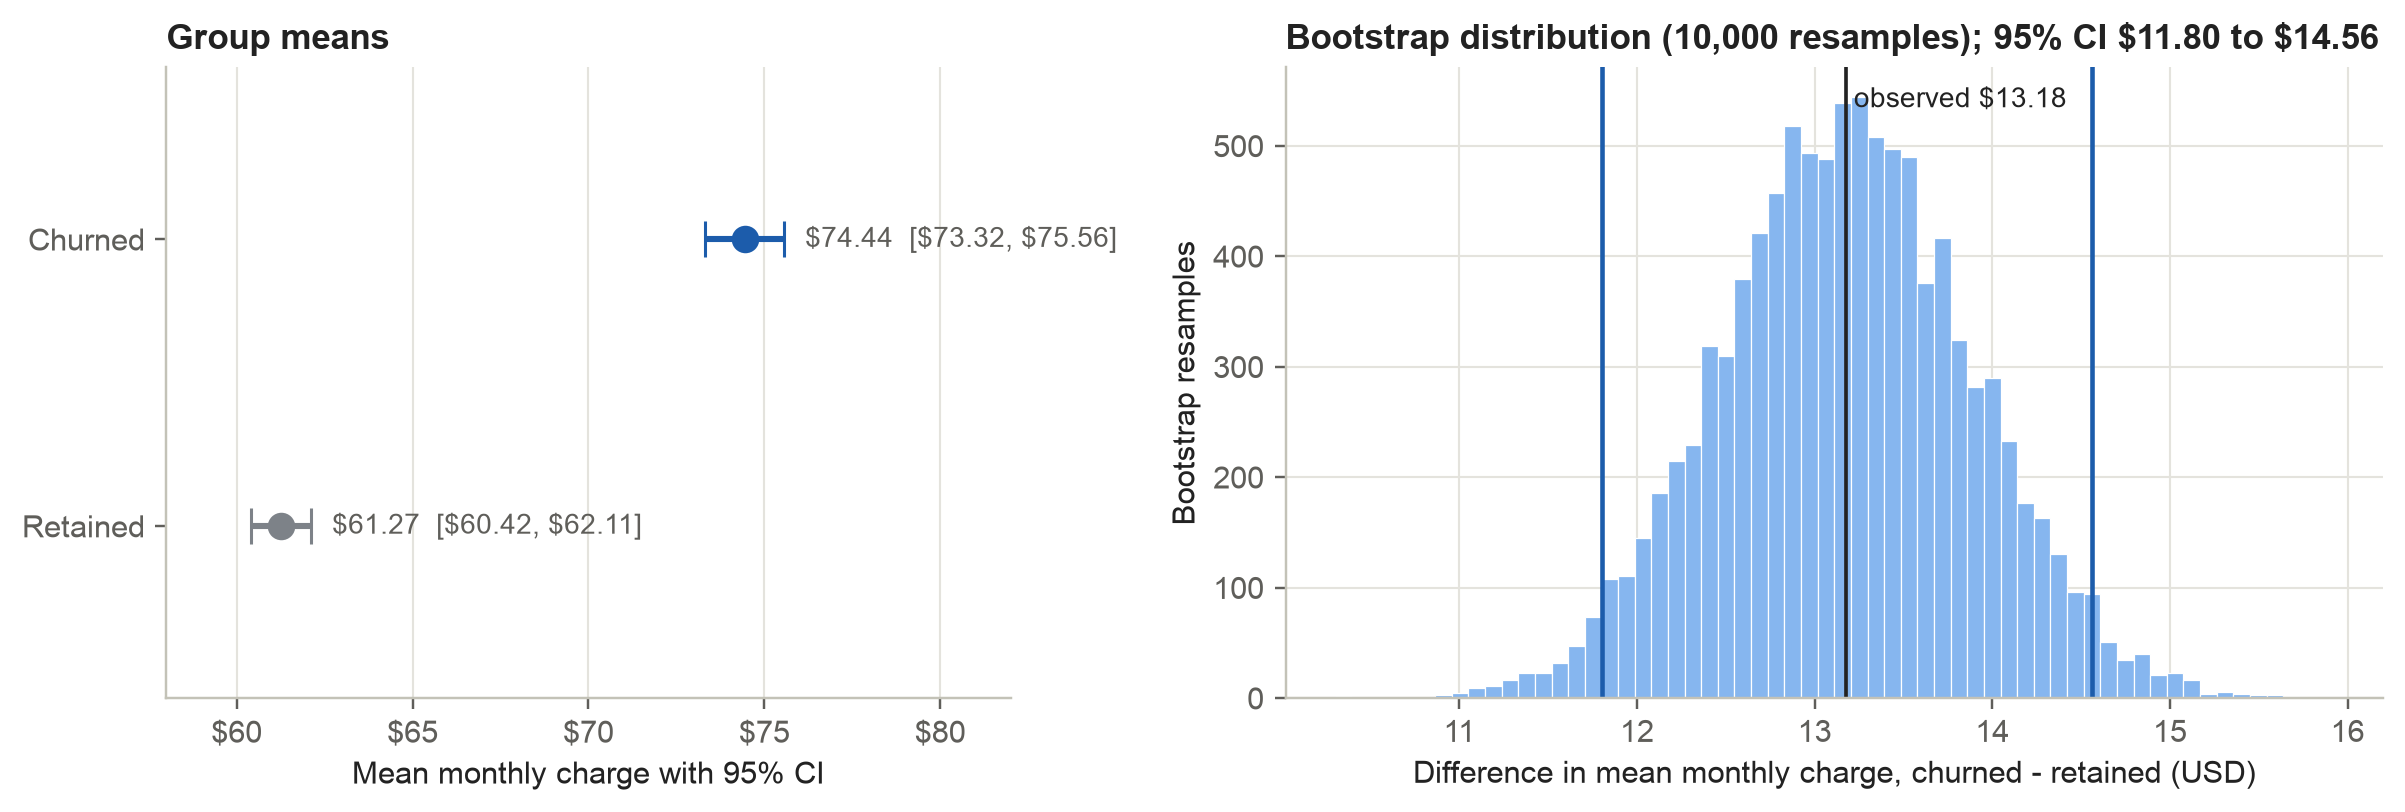

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axes[0]
for position, (name, x, colour) in enumerate((("Retained", retained_charges, RETAINED_COLOR),
                                              ("Churned", churned_charges, CHURN_COLOR))):
    ci = stats.t.interval(1 - ALPHA, len(x) - 1, loc=x.mean(), scale=stats.sem(x))
    ax.errorbar([x.mean()], [position], xerr=[[x.mean() - ci[0]], [ci[1] - x.mean()]], fmt="o",
                color=colour if name == "Churned" else "#7d8288", elinewidth=2, capsize=6, markersize=8)
    ax.text(ci[1] + 0.6, position, f"${x.mean():.2f}  [${ci[0]:.2f}, ${ci[1]:.2f}]", va="center",
            fontsize=9, color=MUTED_INK)
ax.set_yticks([0, 1])
ax.set_yticklabels(["Retained", "Churned"])
ax.set_ylim(-0.6, 1.6)
ax.set_xlim(58, 82)
ax.xaxis.set_major_formatter(StrMethodFormatter("${x:.0f}"))
ax.set_xlabel("Mean monthly charge with 95% CI")
ax.set_title("Group means")
ax.grid(axis="y", visible=False)

ax = axes[1]
ax.hist(bootstrap.bootstrap_distribution, bins=60, color=ORDINAL_BLUES[0], edgecolor="white", linewidth=0.4)
for value in (boot_ci.low, boot_ci.high):
    ax.axvline(value, color=CHURN_COLOR, linewidth=1.5)
ax.axvline(mean_difference, color=INK, linewidth=1.2)
ax.text(mean_difference, ax.get_ylim()[1] * 0.97, f" observed ${mean_difference:.2f}", fontsize=9, va="top")
ax.set_xlabel("Difference in mean monthly charge, churned - retained (USD)")
ax.set_ylabel("Bootstrap resamples")
ax.set_title(f"Bootstrap distribution (10,000 resamples); 95% CI ${boot_ci.low:.2f} to ${boot_ci.high:.2f}")
fig.tight_layout()
save_figure(fig, "fig3_4_mean_difference_ci.png")

#### Is the difference explained by the type of internet service?

Week 2 showed that the overall difference reverses *within* each internet
service. The same Welch comparison is repeated inside each service (three tests,
Holm-adjusted p-values).

In [14]:
service_rows = []
for service in ["No", "DSL", "Fiber optic"]:
    subset = df[df["InternetService"] == service]
    a = subset.loc[subset["Churn"] == "Yes", "MonthlyCharges"].to_numpy()
    b = subset.loc[subset["Churn"] == "No", "MonthlyCharges"].to_numpy()
    res = stats.ttest_ind(a, b, equal_var=False)
    ci = res.confidence_interval(confidence_level=1 - ALPHA)
    service_rows.append({"service": service, "n_churned": len(a), "n_retained": len(b),
                         "mean_churned": a.mean(), "mean_retained": b.mean(),
                         "difference": a.mean() - b.mean(), "ci_low": ci.low, "ci_high": ci.high,
                         "t": res.statistic, "p_value": res.pvalue})
within_service = pd.DataFrame(service_rows)
within_service["p_holm"] = multipletests(within_service["p_value"], method="holm")[1]
show(within_service)
within_service.to_csv(TABLE_DIR / "monthly_charge_difference_within_service.csv", index=False)
results["B_within_service"] = records(within_service)

,service,n_churned,n_retained,mean_churned,mean_retained,difference,ci_low,ci_high,t,p_value,p_holm
0,No,113,1413,20.368,21.136,-0.768,-1.062,-0.474,-5.152,7.66e-07,7.66e-07
1,DSL,459,1962,49.083,60.212,-11.129,-12.566,-9.692,-15.204,5.72e-46,1.72e-45
2,Fiber optic,1297,1799,88.126,93.932,-5.806,-6.678,-4.934,-13.052,7.14e-38,1.43e-37


Saved figure: outputs/figures/fig3_5_mean_difference_within_service.png


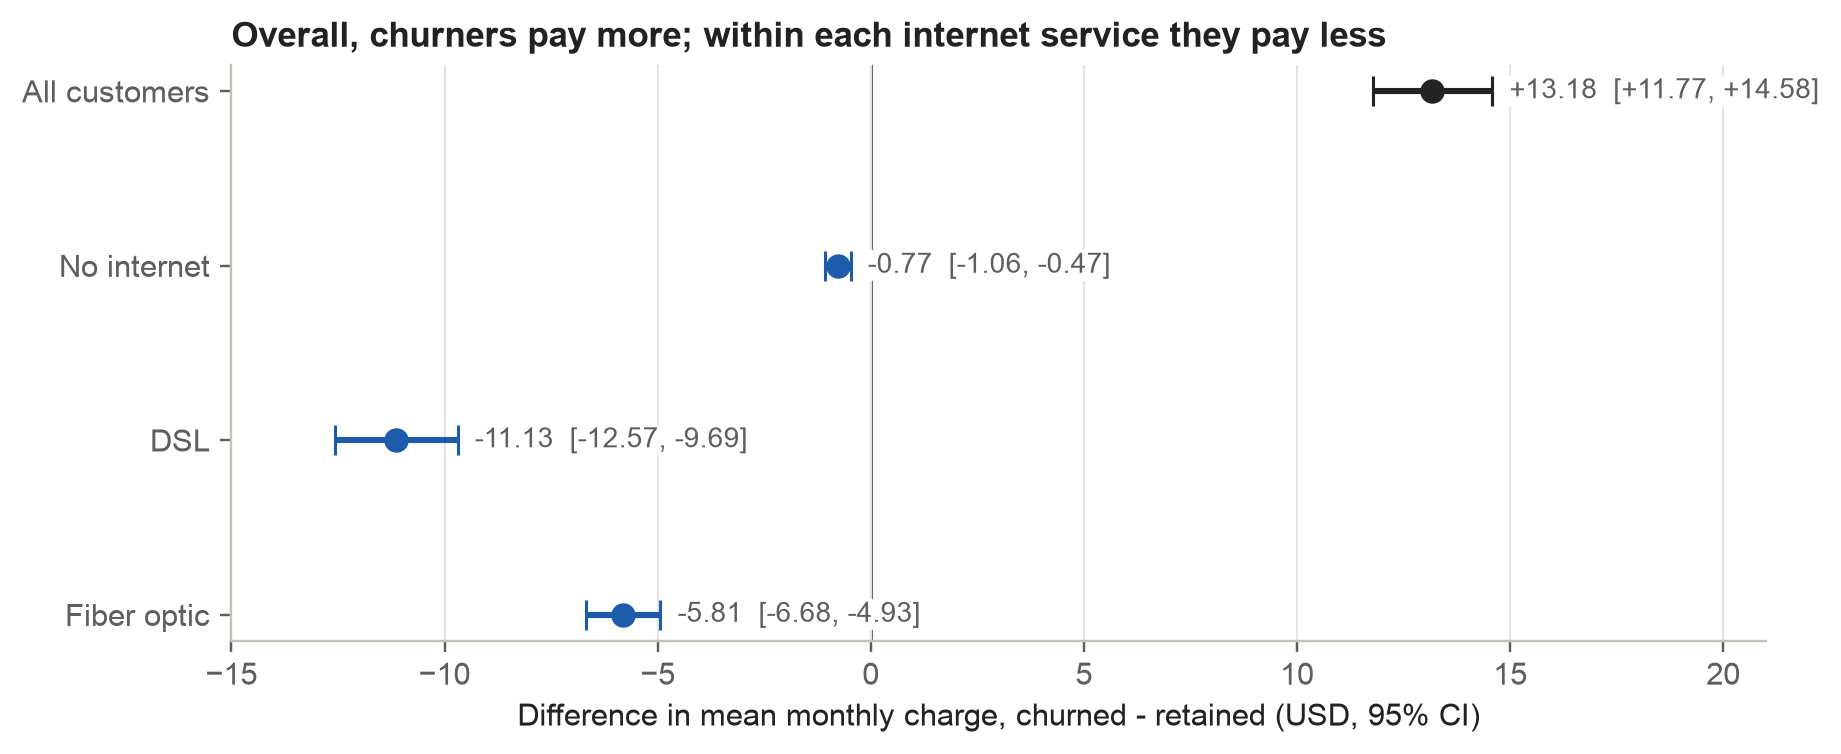

In [15]:
fig, ax = plt.subplots(figsize=(9, 3.4))
labels = ["All customers"] + [f"{'No internet' if s == 'No' else s}" for s in within_service["service"]]
estimates = [mean_difference] + list(within_service["difference"])
lows = [welch_ci.low] + list(within_service["ci_low"])
highs = [welch_ci.high] + list(within_service["ci_high"])
y = np.arange(len(labels))[::-1]
colours = [INK] + [CHURN_COLOR] * 3
for yy, est, lo, hi, colour in zip(y, estimates, lows, highs, colours):
    ax.errorbar([est], [yy], xerr=[[est - lo], [hi - est]], fmt="o", color=colour, elinewidth=2,
                capsize=5, markersize=7)
    ax.text(hi + 0.4, yy, f"{est:+.2f}  [{lo:+.2f}, {hi:+.2f}]", va="center", fontsize=9, color=MUTED_INK,
            bbox=dict(facecolor="white", edgecolor="none", pad=0.8))
ax.axvline(0, color=MUTED_INK, linewidth=1, zorder=0)
ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.set_xlim(-15, 21)
ax.set_xlabel("Difference in mean monthly charge, churned - retained (USD, 95% CI)")
ax.set_title("Overall, churners pay more; within each internet service they pay less")
ax.grid(axis="y", visible=False)
save_figure(fig, "fig3_5_mean_difference_within_service.png")

### Hypothesis C - Security and support add-ons (internet customers)

* **H0:** Among internet customers, the churn rate is the same with and without
  the add-on.
* **H1:** The churn rates differ.

Two related tests (OnlineSecurity, TechSupport), so p-values are Holm-adjusted.

In [16]:
internet = df[df["InternetService"] != "No"]
addon_rows = []
for addon in ["OnlineSecurity", "TechSupport"]:
    without = internet.loc[internet[addon] == "No", "churn_flag"]
    with_addon = internet.loc[internet[addon] == "Yes", "churn_flag"]
    counts, nobs = [without.sum(), with_addon.sum()], [len(without), len(with_addon)]
    z, p = proportions_ztest(counts, nobs)
    lo, hi = confint_proportions_2indep(counts[0], nobs[0], counts[1], nobs[1], method="newcomb")
    rr = (counts[0] / nobs[0]) / (counts[1] / nobs[1])
    addon_rows.append({"add_on": addon, "rate_without_pct": without.mean() * 100, "n_without": nobs[0],
                       "rate_with_pct": with_addon.mean() * 100, "n_with": nobs[1],
                       "difference_pp": (without.mean() - with_addon.mean()) * 100,
                       "ci_low_pp": lo * 100, "ci_high_pp": hi * 100, "risk_ratio": rr, "z": z, "p_value": p})
addon_tests = pd.DataFrame(addon_rows)
addon_tests["p_holm"] = multipletests(addon_tests["p_value"], method="holm")[1]
show(addon_tests)
addon_tests.to_csv(TABLE_DIR / "addon_two_proportion_tests.csv", index=False)
results["C"] = records(addon_tests)

,add_on,rate_without_pct,n_without,rate_with_pct,n_with,difference_pp,ci_low_pp,ci_high_pp,risk_ratio,z,p_value,p_holm
0,OnlineSecurity,41.767,3498,14.611,2019,27.156,24.870,29.362,2.859,20.858,1.29e-96,2.58e-96
1,TechSupport,41.635,3473,15.166,2044,26.469,24.171,28.690,2.745,20.383,2.36e-92,2.36e-92


Saved figure: outputs/figures/fig3_6_addon_difference_ci.png


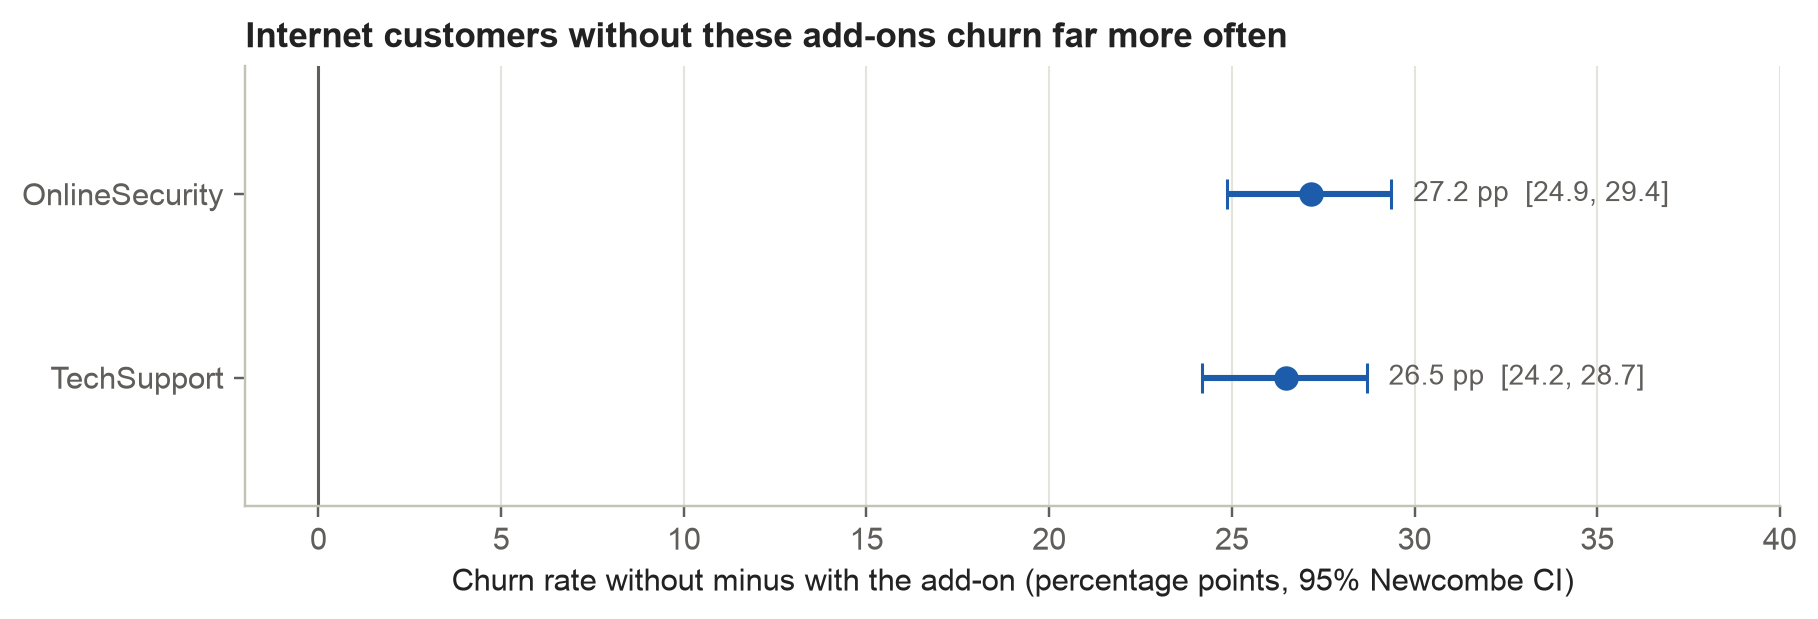

In [17]:
fig, ax = plt.subplots(figsize=(9, 2.6))
y = np.arange(len(addon_tests))[::-1]
ax.errorbar(addon_tests["difference_pp"], y,
            xerr=[addon_tests["difference_pp"] - addon_tests["ci_low_pp"],
                  addon_tests["ci_high_pp"] - addon_tests["difference_pp"]],
            fmt="o", color=CHURN_COLOR, elinewidth=2, capsize=5, markersize=7)
for yy, (_, row) in zip(y, addon_tests.iterrows()):
    ax.text(row["ci_high_pp"] + 0.6, yy, f"{row['difference_pp']:.1f} pp  [{row['ci_low_pp']:.1f}, "
            f"{row['ci_high_pp']:.1f}]", va="center", fontsize=9, color=MUTED_INK)
ax.axvline(0, color=MUTED_INK, linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(addon_tests["add_on"])
ax.set_ylim(-0.7, len(addon_tests) - 0.3)
ax.set_xlim(-2, 40)
ax.set_xlabel("Churn rate without minus with the add-on (percentage points, 95% Newcombe CI)")
ax.set_title("Internet customers without these add-ons churn far more often")
ax.grid(axis="y", visible=False)
save_figure(fig, "fig3_6_addon_difference_ci.png")

### Summary of all tests

In [18]:
summary = pd.DataFrame([
    {"hypothesis": "A: churn vs contract type", "test": "Chi-square test of independence",
     "statistic": f"chi2({dof}) = {chi2:.1f}", "p_value": p_text(p_value),
     "effect_size": f"Cramer's V = {cramers_v:.3f}", "decision": "reject H0" if p_value < ALPHA else "retain H0"},
    {"hypothesis": "A (tenure-adjusted)", "test": "Cochran-Mantel-Haenszel",
     "statistic": f"chi2(1) = {cmh_test.statistic:.1f}", "p_value": p_text(cmh_p),
     "effect_size": f"pooled OR = {pooled_or:.2f} [{pooled_low:.2f}, {pooled_high:.2f}]",
     "decision": "reject H0" if cmh_p < ALPHA else "retain H0"},
    {"hypothesis": "B: monthly charges", "test": "Welch t-test",
     "statistic": f"t({welch.df:.0f}) = {welch.statistic:.2f}", "p_value": p_text(welch.pvalue),
     "effect_size": f"diff = ${mean_difference:.2f}; g = {hedges_g:.2f}",
     "decision": "reject H0" if welch.pvalue < ALPHA else "retain H0"},
    {"hypothesis": "B (robustness)", "test": "Mann-Whitney U",
     "statistic": f"U = {mwu.statistic:,.0f}", "p_value": p_text(mwu.pvalue),
     "effect_size": f"rank-biserial r = {rank_biserial:.2f}",
     "decision": "reject H0" if mwu.pvalue < ALPHA else "retain H0"},
] + [
    {"hypothesis": f"C: {row.add_on}", "test": "Two-proportion z-test",
     "statistic": f"z = {row.z:.2f}", "p_value": p_text(row.p_holm) + " (Holm)",
     "effect_size": f"diff = {row.difference_pp:.1f} pp", "decision": "reject H0" if row.p_holm < ALPHA else "retain H0"}
    for row in addon_tests.itertuples()
])
display(summary)
summary.to_csv(TABLE_DIR / "hypothesis_test_summary.csv", index=False)

with open(RESULTS_DIR / "statistical_results.json", "w") as f:
    json.dump(results, f, indent=2, default=float)
print("Saved outputs/results/statistical_results.json")

,hypothesis,test,statistic,p_value,effect_size,decision
0,A: churn vs contract type,Chi-square test of independence,chi2(2) = 1184.6,5.86e-258,Cramer's V = 0.410,reject H0
1,A (tenure-adjusted),Cochran-Mantel-Haenszel,chi2(1) = 482.8,5.37e-107,"pooled OR = 7.11 [5.87, 8.61]",reject H0
2,B: monthly charges,Welch t-test,t(4136) = 18.41,8.59e-73,diff = $13.18; g = 0.45,reject H0
3,B (robustness),Mann-Whitney U,"U = 6,003,126",3.31e-54,rank-biserial r = 0.24,reject H0
4,C: OnlineSecurity,Two-proportion z-test,z = 20.86,2.58e-96 (Holm),diff = 27.2 pp,reject H0
5,C: TechSupport,Two-proportion z-test,z = 20.38,2.36e-92 (Holm),diff = 26.5 pp,reject H0


Saved outputs/results/statistical_results.json
